In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
import ot
from openTSNE import TSNE
from openTSNE.affinity import Affinities
from scipy.sparse import block_array
from matplotlib.patches import Patch


In [2]:
def get_ring(n, r=1, seed=0):
    np.random.seed(seed)
    theta = np.sort(2 * np.pi * np.random.rand(n))

    r = 1 + 0.2 * np.random.rand(n)
    r *=r

    x = np.cos(theta)
    y = np.sin(theta)

    x *= r
    y *= r
    return np.stack([x,y], axis=1)

def get_blob(n, sig=1, seed=0):
    np.random.seed(seed)

    return np.random.randn(n, 2)*sig

In [30]:
seed = 5 # 2, 5 good

n = 40 # 50
f = 1 # relative size of other batch

ring1 = get_ring(n, seed=seed)
blob1 = get_blob(n, sig=0.5, seed=seed)
batch1 = np.concatenate([ring1, blob1+np.array([5,0])], axis=0)

ring2 = get_ring(n*f, seed=seed+1)
blob2 = get_blob(n*f, sig=0.5, seed=seed+1)
batch2 = np.concatenate([ring2, blob2+np.array([5,0])], axis=0)

batch2 += np.array([0, -4])

In [31]:
# add some high-dim noise for more stable embds

noise_sig = 0.1
noise_dims = 38

batch1 = np.concatenate([batch1, np.random.randn(len(batch1), noise_dims) * noise_sig], axis=1)
batch2 = np.concatenate([batch2, np.random.randn(len(batch2), noise_dims) * noise_sig], axis=1)

In [32]:
def get_edges(nbrs, keys, queries, k):
    _, indices = nbrs.kneighbors(queries)
    indices = indices[:, 1:]
    edges = np.stack([np.repeat(np.arange(len(queries)), k), indices.flatten()], axis=-1)
    segments = np.stack([queries[edges[:, 0]], keys[edges[:, 1]]], axis=1)
    return edges, segments
    

In [45]:
# get knn and mutual knn edges
k = 15

nbrs1 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch1)
edges11, segments11 = get_edges(nbrs1, batch1, batch1, k)
edges12, segments12 = get_edges(nbrs1, batch1, batch2, k)

nbrs2 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch2)
edges21, segments21 = get_edges(nbrs2, batch2, batch1, k)
edges22, segments22 = get_edges(nbrs2, batch2, batch2, k)

sep_graph = sp.coo_matrix((np.ones(len(edges11)+ len(edges22)), 
                           (np.concatenate([edges11[:, 0], edges22[:, 0]+len(batch1)]),
                            np.concatenate([edges11[:, 1], edges22[:, 1]+len(batch1)]))),
                            shape=(len(batch1)+ len(batch2), len(batch1)+ len(batch2)))
sep_graph = sep_graph.maximum(sep_graph.T)


graph12 = sp.coo_matrix(( np.ones(len(edges12)), (edges12[:,0], edges12[:, 1])), shape=(len(batch2), len(batch1)))
graph21 = sp.coo_matrix(( np.ones(len(edges21)), (edges21[:,1], edges21[:, 0])), shape=(len(batch2), len(batch1)))
m_graph = graph12.minimum(graph21).tocoo()

sep_m_graph = sep_graph +  block_array([[None, m_graph],
                                        [m_graph.T,  None],],
                                       format="csr")
sep_m_graph /= sep_m_graph.sum()


m_edges = np.stack([m_graph.row, m_graph.col], axis=-1)
m_segments = np.stack([batch2[m_edges[:, 0]], batch1[m_edges[:, 1]]], axis=1)


In [46]:

def sparsify_plan(P, mode=None, k=15):
    if mode is None:
        P_sparse = P

    elif mode == "topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = 1
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = 1

    elif mode == "weighted_topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = P[i, idx]
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = P[idx, j]
    else:

        raise NotImplementedError

    return P_sparse

In [47]:
# get ot plan

dist = ot.dist(batch1, batch2)

eps = np.median(dist) / 200

P = ot.sinkhorn(np.ones(len(batch1))/len(batch1), 
                np.ones(len(batch2))/len(batch2),
                        dist,
                        reg=eps,
                        numItermax=3000,
                        stopThr=1e-12)

P_sp = sp.coo_matrix(sparsify_plan(P, mode="topk", k=k))

ot_segments = np.stack([batch1[P_sp.row], batch2[P_sp.col]], axis=1)

sep_ot_graph = sep_graph +  block_array([[None, P_sp],
                                        [P_sp.T,  None],],
                                       format="csr")
sep_ot_graph /= sep_ot_graph.sum()

# only normalize sep_graph here so not have it dwarfed by the off-diag blocks
sep_graph /= sep_graph.sum()

/home/sdamrich/miniconda3/envs/stdenv/lib/python3.10/site-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [53]:
def subsample(x, num, seed=seed):
    np.random.seed(seed)
    r = np.random.randn(len(x))
    part = np.argsort(r)
    if isinstance(num, int):
        n = num
    else:
        n = np.floor(len(x)*num).astype(int)
    return x[part[:num]]


In [49]:
# get embeddings

# normal tsne
sep_aff = Affinities()
sep_aff.P = sep_graph
embedder = TSNE(
    n_components=2,
    random_state=seed,
    verbose=False,
)
joint_tsne = embedder.fit(affinities=sep_aff, initialization=np.concatenate([batch1, batch2])[:, :2]/10000)


m_aff = Affinities()
m_aff.P = sep_m_graph
embedder_m = TSNE(
    n_components=2,
    random_state=seed,
    verbose=False,
)
m_tsne = embedder_m.fit(affinities=m_aff, initialization=np.concatenate([batch1, batch2])[:, :2]/10000)


ot_aff = Affinities()
ot_aff.P = sep_ot_graph
embedder_ot = TSNE(
    n_components=2,
    random_state=seed,
    verbose=False,
)
ot_tsne = embedder_ot.fit(affinities=ot_aff, initialization=np.concatenate([batch1, batch2])[:, :2]/10000)

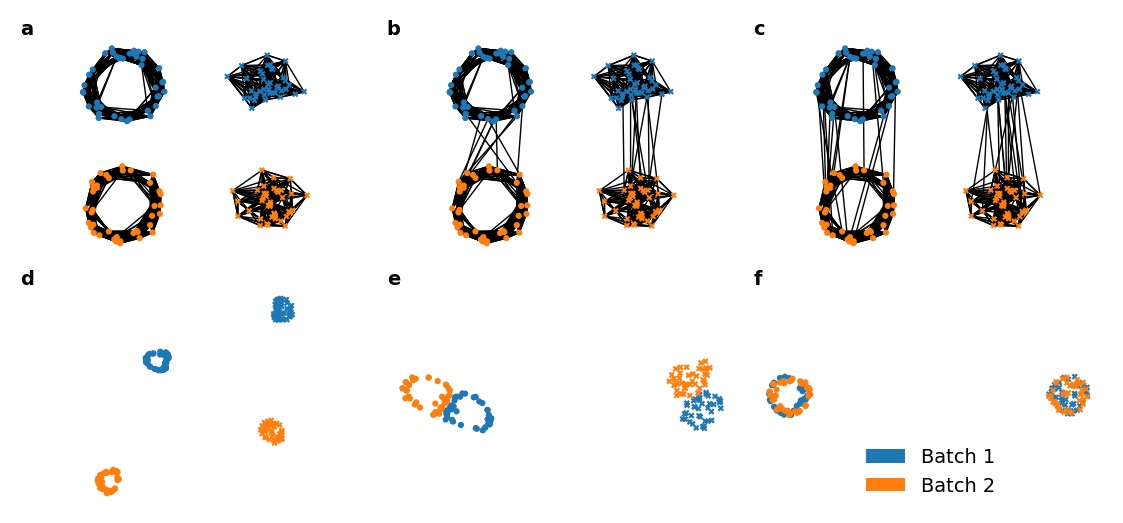

In [52]:
fig, ax = plt.subplots(ncols=3, nrows=2, figsize=(5.5, 2.5), dpi=200, constrained_layout=True)

s=5



ax[0,0].scatter(*batch1[:n, :2].T, c="C0", edgecolors="none",  s=s)
ax[0,0].scatter(*batch1[n:, :2].T, c="C0", edgecolors="none",  marker="X", s=s)

ax[0,0].scatter(*batch2[:n, :2].T, c="C1", edgecolors="none", s=s)
ax[0,0].scatter(*batch2[n:, :2].T, c="C1", edgecolors="none", marker="X", s=s)

ax[0,0].add_collection(LineCollection(segments11[:, :, :2], linewidths=0.5, color="k", zorder=-1))
ax[0,0].add_collection(LineCollection(segments22[:, :, :2], linewidths=0.5, color="k", zorder=-1))


ax[0, 1].scatter(*batch1[:n, :2].T,  c="C0", edgecolors="none", s=s)
ax[0, 1].scatter(*batch1[n:, :2].T,  c="C0", edgecolors="none",  marker="X", s=s)

ax[0, 1].scatter(*batch2[:n, :2].T, c="C1", edgecolors="none", s=s)
ax[0, 1].scatter(*batch2[n:, :2].T, c="C1", edgecolors="none",  marker="X", s=s)

ax[0, 1].add_collection(LineCollection(segments11[:, :, :2], linewidths=0.5, color="k", zorder=-1))
ax[0, 1].add_collection(LineCollection(segments22[:, :, :2], linewidths=0.5, color="k", zorder=-1))
ax[0, 1].add_collection(LineCollection(subsample(m_segments[:, :, :2], num=20, seed=seed+2), linewidths=0.5, color="k", zorder=-1))

ax[0, 2].scatter(*batch1[:n, :2].T, c="C0", edgecolors="none",  s=s)
ax[0, 2].scatter(*batch1[n:, :2].T, c="C0", edgecolors="none",  marker="X", s=s)
ax[0, 2].scatter(*batch2[:n, :2].T, c="C1", edgecolors="none", s=s)
ax[0, 2].scatter(*batch2[n:, :2].T, c="C1", edgecolors="none",  marker="X", s=s)

ax[0, 2].add_collection(LineCollection(segments11[:, :, :2], linewidths=0.5, color="k", zorder=-1))
ax[0, 2].add_collection(LineCollection(segments22[:, :, :2], linewidths=0.5, color="k", zorder=-1))
ax[0, 2].add_collection(LineCollection(subsample(ot_segments[:, :, :2], num=30, seed=seed+2), linewidths=0.5, color="k", zorder=-1))
#ax[0, 2].add_collection(LineCollection(ot_segments[:, :, :2], linewidths=0.5, color="k", zorder=-1))


ax[1,0].scatter(*joint_tsne[:n].T,  c="C0", edgecolors="none",  s=s)
ax[1,0].scatter(*joint_tsne[n:2*n].T,  c="C0", edgecolors="none",  marker="X",s=s)

ax[1,0].scatter(*joint_tsne[2*n:3*n].T, c="C1", edgecolors="none", s=s)
ax[1,0].scatter(*joint_tsne[3*n:].T, c="C1", edgecolors="none",  marker="X", s=s)



ax[1,1].scatter(*m_tsne[:n].T, c="C0", edgecolors="none",s=s)
ax[1,1].scatter(*m_tsne[n:2*n].T, c="C0", edgecolors="none",  marker="X",s=s)

ax[1,1].scatter(*m_tsne[2*n:3*n].T, c="C1", edgecolors="none", s=s)
ax[1,1].scatter(*m_tsne[3*n:].T, c="C1", edgecolors="none",  marker="X",  s=s)

ax[1,2].scatter(*ot_tsne[:n].T, c="C0", edgecolors="none", s=s)
ax[1,2].scatter(*ot_tsne[n:2*n].T, c="C0", edgecolors="none",  marker="X",s=s)

ax[1,2].scatter(*ot_tsne[2*n:3*n].T, c="C1", edgecolors="none",s=s)
ax[1,2].scatter(*ot_tsne[3*n:].T, c="C1", edgecolors="none",  marker="X",s=s)


letters = "abcdefghij"
for i, cax in enumerate(ax.flatten()):
    cax.axis("off")
    cax.set_aspect("equal", "datalim")

    cax.text(
    0.0,
    1.0,
    f"{letters[i]}",
    transform=cax.transAxes,
    ha="left",
    va="bottom",
    fontweight="bold",
    fontsize=7
)
    
handles = [
    Patch(facecolor="C0", label="Batch 1"),
    Patch(facecolor="C1", label="Batch 2"),
]

ax[1,2].legend(handles=handles, loc=(0.3, 0.0), frameon=False,  fontsize=7)

fig.savefig("fig1.pdf", dpi=300)